In [160]:
import pandas as pd

columns = [
    "checking_account", "duration", "credit_history",
    "purpose", "credit_amount", "savings",
    "employment", "installment_rate", "personal_status",
    "other_debtors", "residence_since", "property",
    "age", "other_installment_plans", "housing",
    "existing_credits", "job", "dependents",
    "telephone", "foreign_worker", "target"
]

df = pd.read_csv(
    "../data/german.data",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [161]:
# Check column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Check data types
print("\nDATA TYPES:")
print(df.dtypes)

# Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Check target distribution
print("\nTARGET DISTRIBUTION:")
print(df["target"].value_counts())

COLUMN NAMES:
['checking_account', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker', 'target']

DATA TYPES:
checking_account             str
duration                   int64
credit_history               str
purpose                      str
credit_amount              int64
savings                      str
employment                   str
installment_rate           int64
personal_status              str
other_debtors                str
residence_since            int64
property                     str
age                        int64
other_installment_plans      str
housing                      str
existing_credits           int64
job                          str
dependents                 int64
telephone                    str
foreign_worker              

In [162]:
# Check missing values
print("Total missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Summary of numerical columns
display(df.describe())

# Target distribution in percentage
print("\nTarget distribution (%):")
print(df["target"].value_counts(normalize=True) * 100)

Total missing values: 0
Duplicate rows: 0


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,dependents,target
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000



Target distribution (%):
target
1    70.0
2    30.0
Name: proportion, dtype: float64


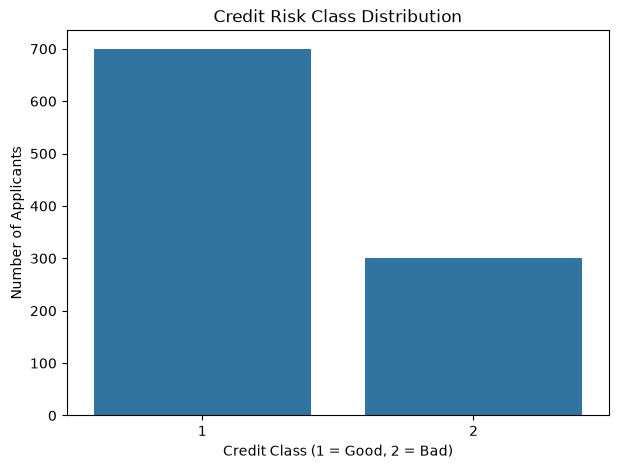

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="target"
)

plt.title("Credit Risk Class Distribution")
plt.xlabel("Credit Class (1 = Good, 2 = Bad)")
plt.ylabel("Number of Applicants")

plt.show()

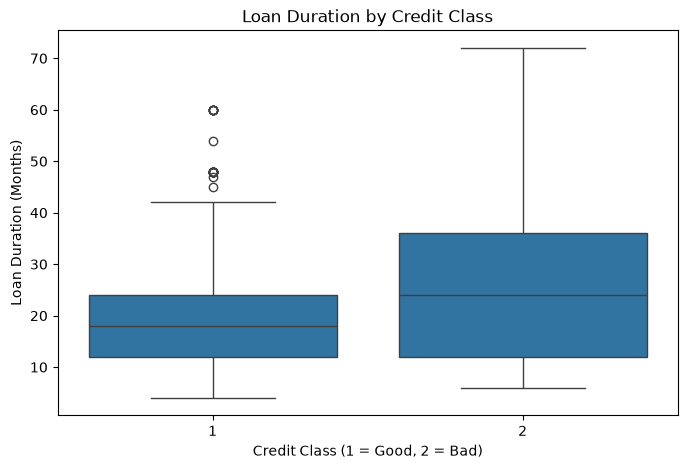

In [164]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target",
    y="duration"
)

plt.title("Loan Duration by Credit Class")
plt.xlabel("Credit Class (1 = Good, 2 = Bad)")
plt.ylabel("Loan Duration (Months)")

plt.show()

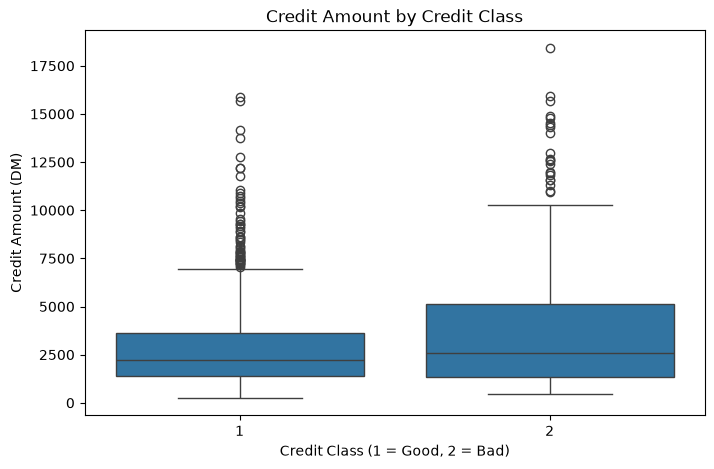

In [165]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target",
    y="credit_amount"
)

plt.title("Credit Amount by Credit Class")
plt.xlabel("Credit Class (1 = Good, 2 = Bad)")
plt.ylabel("Credit Amount (DM)")

plt.show()

In [166]:
# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

Features shape: (1000, 20)
Target shape: (1000,)

Input features:
['checking_account', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker']

Target classes:
[1 2]


In [167]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training records:", len(y_train))
print("Testing records:", len(y_test))

Training features: (800, 20)
Testing features: (200, 20)
Training records: 800
Testing records: 200


In [168]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_columns = X.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_columns),
        ("numerical", "passthrough", numerical_columns)
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Categorical features:", len(categorical_columns))
print("Numerical features:", len(numerical_columns))
print("Training data after encoding:", X_train_encoded.shape)
print("Testing data after encoding:", X_test_encoded.shape)

Categorical features: 13
Numerical features: 7
Training data after encoding: (800, 61)
Testing data after encoding: (200, 61)


In [169]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(max_iter=2000)

model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.79

Classification Report:
              precision    recall  f1-score   support

           1       0.83      0.89      0.86       140
           2       0.68      0.57      0.62        60

    accuracy                           0.79       200
   macro avg       0.75      0.73      0.74       200
weighted avg       0.78      0.79      0.78       200



d:\ML PROJECT\credit-risk-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [170]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# End-to-end Pipeline: Preprocessing -> Scaling -> Classifier
scaled_model = Pipeline([
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LogisticRegression(max_iter=5000))
])

scaled_model.fit(X_train, y_train)

y_pred_scaled = scaled_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_scaled))
print(classification_report(y_test, y_pred_scaled))


Accuracy: 0.775
              precision    recall  f1-score   support

           1       0.83      0.86      0.84       140
           2       0.64      0.58      0.61        60

    accuracy                           0.78       200
   macro avg       0.73      0.72      0.73       200
weighted avg       0.77      0.78      0.77       200



In [171]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_encoded, y_train)

y_pred_rf = rf_model.predict(X_test_encoded)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.73

Classification Report:
              precision    recall  f1-score   support

           1       0.81      0.80      0.81       140
           2       0.55      0.57      0.56        60

    accuracy                           0.73       200
   macro avg       0.68      0.68      0.68       200
weighted avg       0.73      0.73      0.73       200



In [172]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_scaled, labels=[1, 2])

print("Confusion Matrix:")
print(cm)

# Rows = actual classes [Good, Bad]
# Columns = predicted classes [Good, Bad]

false_good = cm[1, 0]  # Bad applicant predicted as Good
false_bad = cm[0, 1]   # Good applicant predicted as Bad

total_cost = (false_good * 5) + (false_bad * 1)

print("\nBad predicted as Good:", false_good)
print("Good predicted as Bad:", false_bad)
print("Total misclassification cost:", total_cost)

Confusion Matrix:
[[120  20]
 [ 25  35]]

Bad predicted as Good: 25
Good predicted as Bad: 20
Total misclassification cost: 145


In [173]:
from sklearn.metrics import confusion_matrix

# Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_scaled, labels=[1, 2])
cost_lr = cm_lr[1, 0] * 5 + cm_lr[0, 1]

# Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[1, 2])
cost_rf = cm_rf[1, 0] * 5 + cm_rf[0, 1]

print("Logistic Regression cost:", cost_lr)
print("Random Forest cost:", cost_rf)

Logistic Regression cost: 145
Random Forest cost: 158


In [174]:
from sklearn.metrics import confusion_matrix

# Probability that each applicant belongs to class 2 (Bad Credit)
bad_prob = scaled_model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6]:
    predictions = (bad_prob >= threshold).astype(int)
    predictions = predictions + 1  # Convert 0/1 to classes 1/2

    cm = confusion_matrix(y_test, predictions, labels=[1, 2])
    cost = cm[1, 0] * 5 + cm[0, 1]

    print(f"Threshold: {threshold}")
    print(f"Error cost: {cost}")
    print(cm)
    print()


Threshold: 0.3
Error cost: 100
[[100  40]
 [ 12  48]]

Threshold: 0.4
Error cost: 116
[[114  26]
 [ 18  42]]

Threshold: 0.5
Error cost: 145
[[120  20]
 [ 25  35]]

Threshold: 0.6
Error cost: 190
[[130  10]
 [ 36  24]]



In [175]:
from sklearn.metrics import classification_report

threshold = 0.3

predictions = (bad_prob >= threshold).astype(int) + 1

print(classification_report(
    y_test,
    predictions,
    labels=[1, 2],
    target_names=["Good Credit", "Bad Credit"]
))

              precision    recall  f1-score   support

 Good Credit       0.89      0.71      0.79       140
  Bad Credit       0.55      0.80      0.65        60

    accuracy                           0.74       200
   macro avg       0.72      0.76      0.72       200
weighted avg       0.79      0.74      0.75       200



In [176]:
import joblib

final_model = {
    "model": scaled_model,
    "threshold": 0.3,
    "target_mapping": {
        1: "Good Credit",
        2: "Bad Credit"
    }
}

joblib.dump(final_model, "../models/credit_risk_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [177]:
import joblib

loaded_model = joblib.load(
    "../models/credit_risk_model.pkl"
)

print("Model loaded successfully!")
print("Threshold:", loaded_model["threshold"])
print("Classes:", loaded_model["target_mapping"])

Model loaded successfully!
Threshold: 0.3
Classes: {1: 'Good Credit', 2: 'Bad Credit'}


In [178]:
def predict_credit_risk(applicant_data):
    # Convert applicant information into a DataFrame
    applicant_df = pd.DataFrame(
        [applicant_data],
        columns=X.columns
    )

    # Load model and threshold
    model = loaded_model["model"]
    threshold = loaded_model["threshold"]

    # Predict probability of Bad Credit (class 2)
    probabilities = model.predict_proba(applicant_df)
    bad_index = list(model.classes_).index(2)
    bad_probability = probabilities[0, bad_index]

    # Apply threshold
    prediction = 2 if bad_probability >= threshold else 1

    return {
        "prediction": loaded_model["target_mapping"][prediction],
        "bad_credit_probability": round(float(bad_probability), 3)
    }

print("Prediction function created successfully!")

# Test prediction with sample applicant data
sample_applicant = X.iloc[0].to_dict()
print("Sample applicant prediction test:", predict_credit_risk(sample_applicant))


Prediction function created successfully!
